# Email & SMS Spam Detection System
### End-to-End NLP & Machine Learning Classification Pipeline

This notebook documents the complete machine learning workflow to classify messages as **Legitimate (Ham)** or **Spam**:
1. **Data Ingestion & Cleaning**: Handling tab-separated text data, duplicate detection, and deduplication.
2. **Exploratory Data Analysis (EDA)**: Class distributions, character/word/sentence length statistics, and semantic word clouds.
3. **Text Preprocessing**: Normalization, punctuation removal, regex cleaning, stopword filtering, and lemmatization.
4. **Feature Engineering**: Converting textual features into numerical vectors using TF-IDF vectorization (3,000 features).
5. **Model Benchmarking & Ensembling**: Evaluating `BernoulliNB`, `ComplementNB`, `MultinomialNB`, and building a Majority Voting Ensemble.
6. **Model Serialization**: Exporting production-ready pickled model and vectorizer artifacts.


## 1. Environment Setup & Data Ingestion
Importing core data manipulation, NLP, and visualization libraries, and loading `spam.txt`.


In [1]:
import numpy as np
import pandas as pd
import re
import string
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#supress display of warnings
import warnings
warnings.filterwarnings('ignore')


In [2]:
data = pd.read_csv('spam.txt', sep = '\t', names =['label', 'message'])
data.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Data Cleaning & Inspection
Checking dataset dimensions, inspecting for null/missing values, and removing duplicate entries.


In [3]:
data.shape


(5572, 2)

In [4]:
data.isnull().sum()


label      0
message    0
dtype: int64

In [5]:
data.duplicated().sum()


np.int64(403)

In [6]:
data = data.drop_duplicates()
data.duplicated().sum()


np.int64(0)

In [7]:
data.shape


(5169, 2)

## 3. Exploratory Data Analysis (EDA)
Analyzing class distributions, message length characteristics, and vocabulary patterns.


### 3.1 Class Distribution Analysis


In [8]:
data['label'].value_counts()


label
ham     4516
spam     653
Name: count, dtype: int64

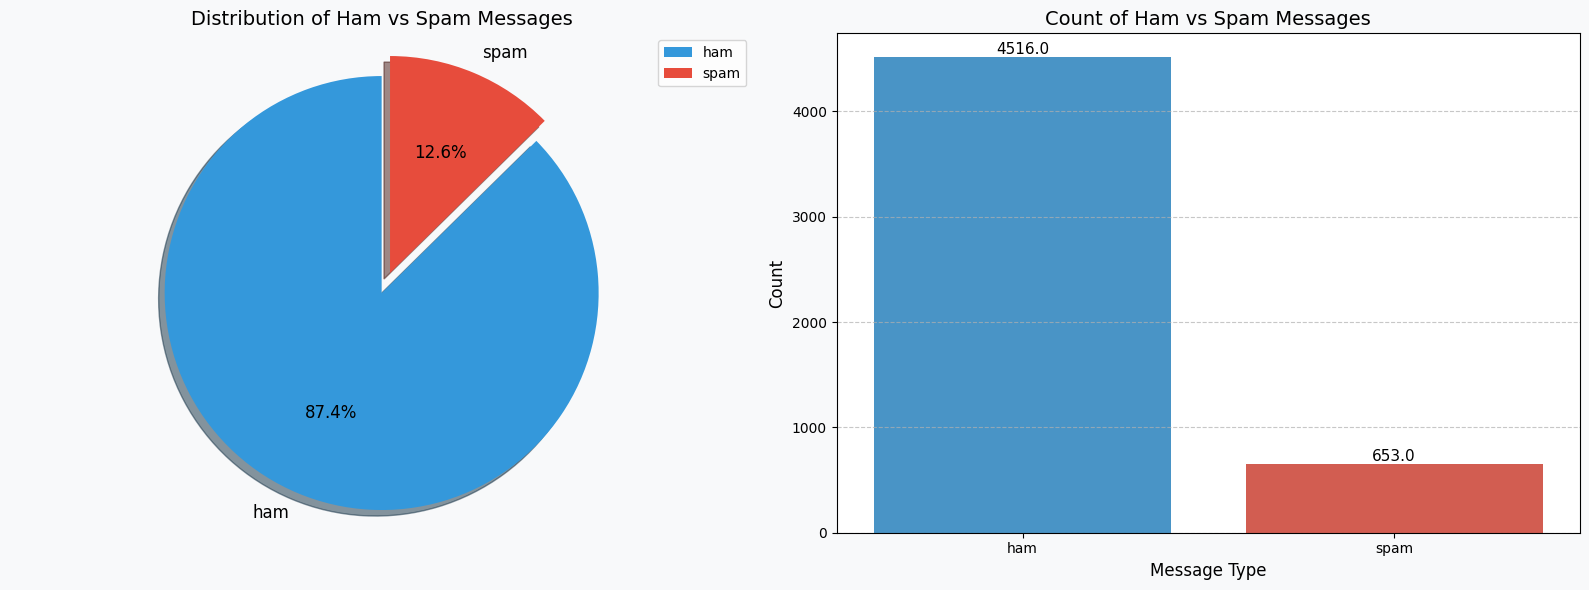

In [9]:
# Create both visualizations side by side with vibrant colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Define vibrant, pleasing colors
ham_color = '#3498db'  # Bright blue
spam_color = '#e74c3c'  # Vibrant red
colors = [ham_color, spam_color]

# Pie chart
labels = data['label'].value_counts().index
sizes = data['label'].value_counts().values
explode = (0, 0.1)  # explode the 2nd slice (spam)

ax1.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
       shadow=True, startangle=90, textprops={'fontsize': 12})
ax1.axis('equal')
ax1.set_title('Distribution of Ham vs Spam Messages', fontsize=14)
ax1.legend(labels, loc="upper right")

# Bar chart
sns.countplot(x='label', data=data, palette=colors, ax=ax2)

# Add count labels on top of bars
for p in ax2.patches:
    ax2.annotate(f'{p.get_height()}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

ax2.set_title('Count of Ham vs Spam Messages', fontsize=14)
ax2.set_xlabel('Message Type', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# Add a background color to enhance visual appeal
fig.set_facecolor('#f8f9fa')  # Light gray background
plt.tight_layout()
plt.show()


> **Observation**: There is a severe class imbalance (~87.4% Ham vs ~12.6% Spam). In spam filtering, **Precision** on Spam is the most critical metric to prevent legitimate personal or banking emails from being falsely flagged as spam.


### 3.2 Text Length Feature Engineering
Extracting character, word, and sentence counts for each message.


In [10]:
data['num_character'] = data['message'].apply(len)
data.head()


,label,message,num_character
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [11]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt to
[nltk_data]     /Users/destructor/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/destructor/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/destructor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/destructor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/destructor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [12]:
from nltk.tokenize import word_tokenize
data['message'].apply(lambda x: word_tokenize(x))


0       [Go, until, jurong, point, ,, crazy, .., Avail...
1                [Ok, lar, ..., Joking, wif, u, oni, ...]
2       [Free, entry, in, 2, a, wkly, comp, to, win, F...
3       [U, dun, say, so, early, hor, ..., U, c, alrea...
4       [Nah, I, do, n't, think, he, goes, to, usf, ,,...
                              ...                        
5567    [This, is, the, 2nd, time, we, have, tried, 2,...
5568      [Will, ü, b, going, to, esplanade, fr, home, ?]
5569    [Pity, ,, *, was, in, mood, for, that, ., So, ...
5570    [The, guy, did, some, bitching, but, I, acted,...
5571                  [Rofl, ., Its, true, to, its, name]
Name: message, Length: 5169, dtype: object

In [13]:
data['num_words'] = data['message'].apply(lambda x: len(nltk.word_tokenize(x)))
data.head()


,label,message,num_character,num_words
0,ham,"Go until jurong point, crazy.. Available only ...",111,24
1,ham,Ok lar... Joking wif u oni...,29,8
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,ham,U dun say so early hor... U c already then say...,49,13
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,15


In [14]:
data['num_sentences'] = data['message'].apply(lambda x: len(nltk.sent_tokenize(x)))
data.head()


,label,message,num_character,num_words,num_sentences
0,ham,"Go until jurong point, crazy.. Available only ...",111,24,2
1,ham,Ok lar... Joking wif u oni...,29,8,2
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,ham,U dun say so early hor... U c already then say...,49,13,1
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,15,1


### 3.3 Statistical Comparison of Ham vs Spam Messages


In [15]:
data[data['label'] == 'ham'][['num_character', 'num_words', 'num_sentences']].describe()


,num_character,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.905890,17.267715,1.827724
std,56.715046,13.588065,1.394338
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,53.000000,13.000000,1.000000
75%,91.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [16]:
data[data['label'] == 'spam'][['num_character', 'num_words', 'num_sentences']].describe()


,num_character,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.704441,27.762634,2.986217
std,29.821348,6.993008,1.494815
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,148.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,223.000000,46.000000,9.000000


> **Statistical Finding**: On average, **spam messages are significantly longer** than ham messages (mean of 137.7 characters vs. 70.9 characters). Spammers maximize the ~160-character SMS limit to include promotional bait, contact numbers, and calls-to-action. Ham messages have a lower median length (53 characters), though a few personal essays create extreme outliers up to 910 characters.


### 3.4 Visualizing Length Distributions (Histograms & KDEs)


<Axes: xlabel='num_character', ylabel='Count'>

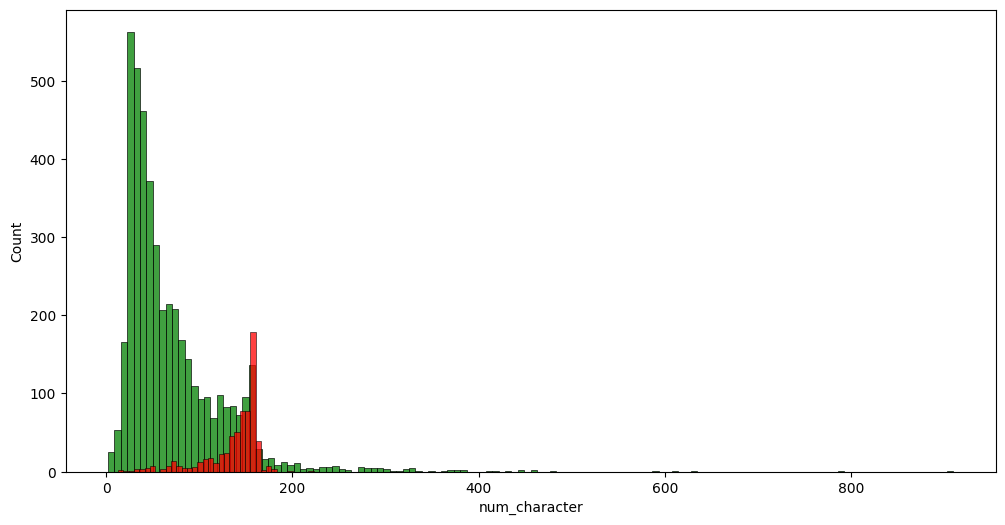

In [17]:
plt.figure(figsize=(12, 6))
sns.histplot(data[data['label'] == 'ham']['num_character'], color = 'green')
sns.histplot(data[data['label'] == 'spam']['num_character'], color = 'red')


<Axes: xlabel='num_words', ylabel='Count'>

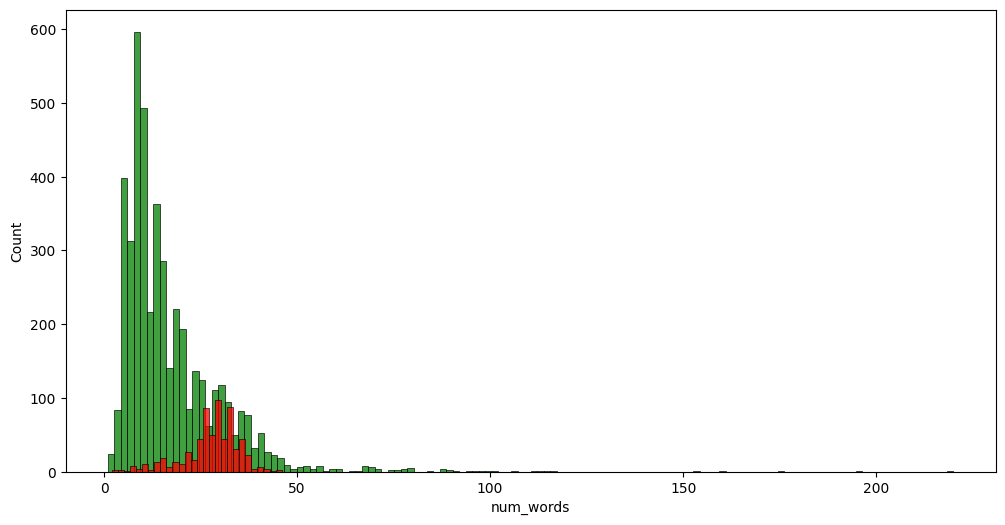

In [18]:
plt.figure(figsize=(12, 6))
sns.histplot(data[data['label'] == 'ham']['num_words'], color = 'green')
sns.histplot(data[data['label'] == 'spam']['num_words'], color = 'red')


<Axes: xlabel='num_sentences', ylabel='Count'>

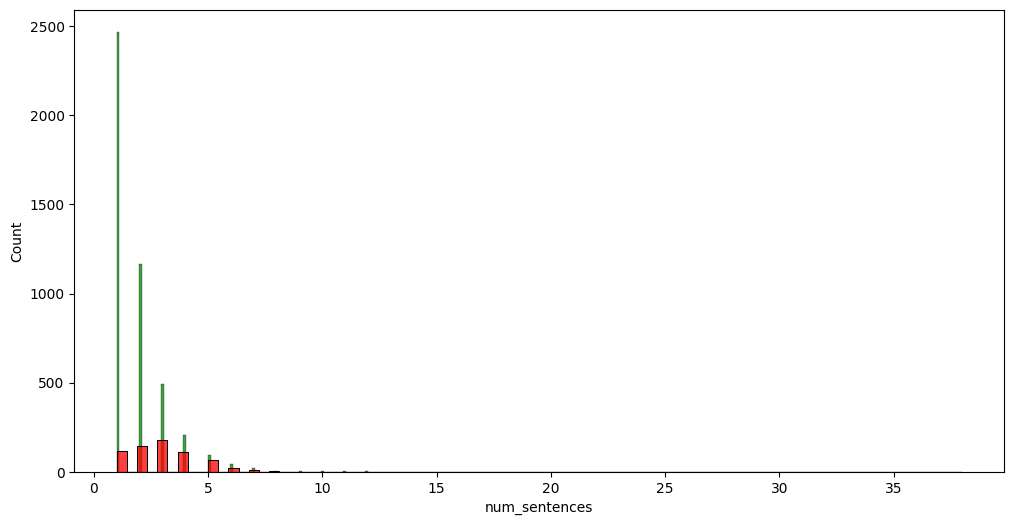

In [19]:
plt.figure(figsize=(12, 6))
sns.histplot(data[data['label'] == 'ham']['num_sentences'], color = 'green')
sns.histplot(data[data['label'] == 'spam']['num_sentences'], color = 'red')


### 3.5 Semantic Word Clouds


In [20]:
from wordcloud import WordCloud


In [21]:
ham_msg_txt = data[data['label'] == 'ham']['message']
spam_msg_txt = data[data['label'] == 'spam']['message']


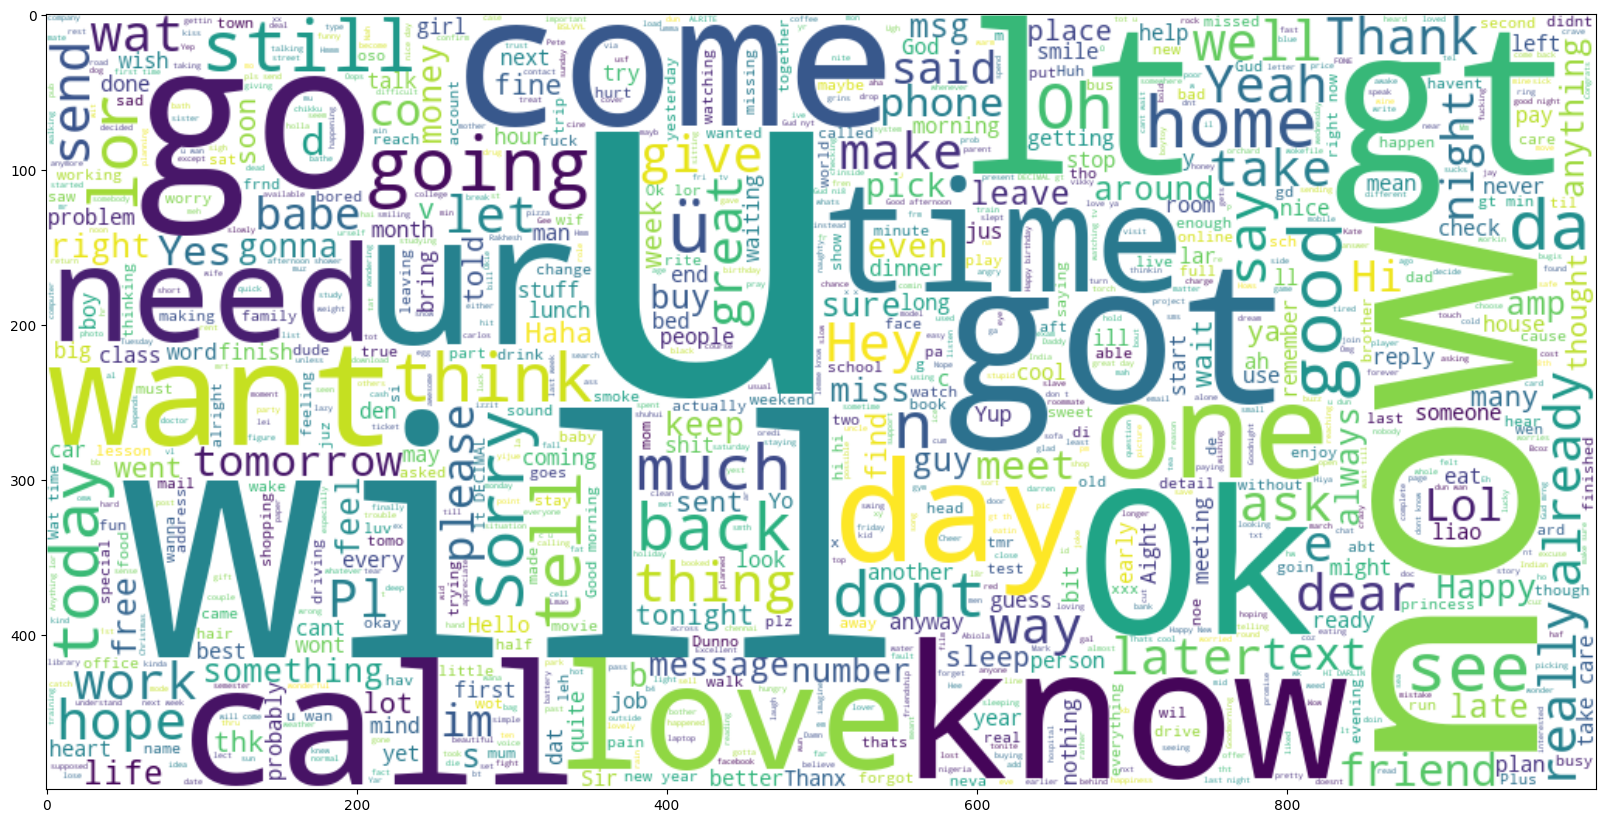

In [22]:
plt.figure(figsize = (20, 20))

wc = WordCloud(background_color='white', width=1000, height=500, max_words=2500).generate(" ".join(ham_msg_txt))
plt.imshow(wc, interpolation='bilinear')


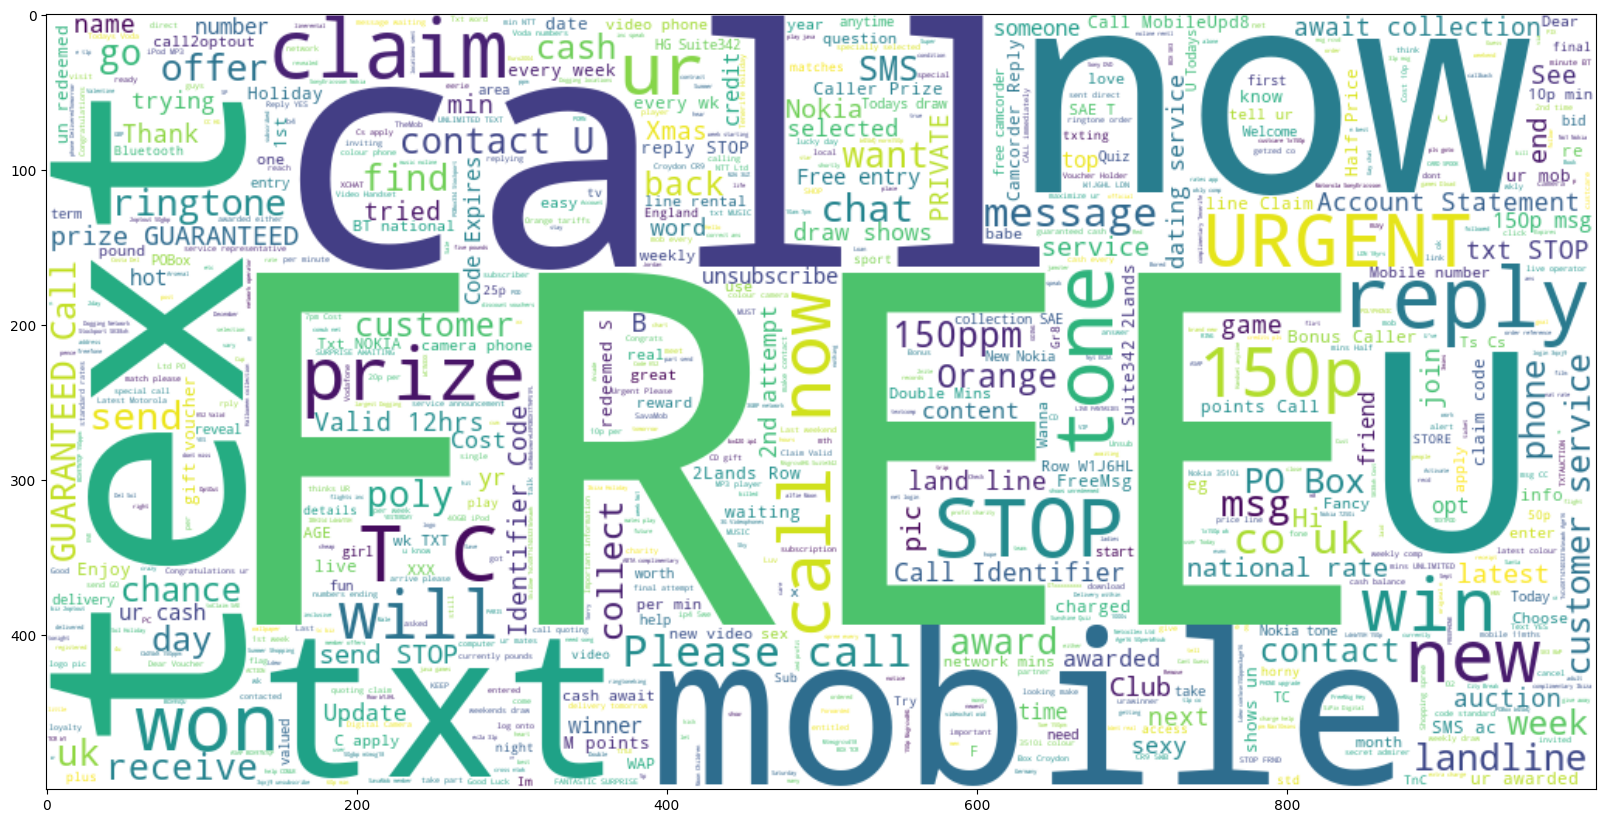

In [23]:
plt.figure(figsize = (20, 20))

wc = WordCloud(background_color='white', width=1000, height=500, max_words=2500).generate(" ".join(spam_msg_txt))
plt.imshow(wc, interpolation='bilinear')


## 4. Text Preprocessing Pipeline
Normalizing raw text through lowercasing, punctuation stripping, special character removal, stopword filtering, and lemmatization.


In [24]:
x = data['message'][5]
y = data['label'][5]

x, y


("FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",
 'spam')

### 4.1 Punctuation Removal


In [25]:
def remove_punctuation(text):
    trans = str.maketrans('', '', string.punctuation)
    return text.translate(trans)


In [26]:
data['message'] = data['message'].apply(remove_punctuation)


In [27]:
x = data['message'][5]
y = data['label'][5]

x, y


('FreeMsg Hey there darling its been 3 weeks now and no word back Id like some fun you up for it still Tb ok XxX std chgs to send £150 to rcv',
 'spam')

### 4.2 Special Character Removal


In [28]:
def remove_sp_ch(text):
    t = re.sub('[^a-zA-Z]', ' ', text)
    return t


In [29]:
data['message'] = data['message'].apply(remove_sp_ch)


In [30]:
x = data['message'][5]
y = data['label'][5]

x, y


('FreeMsg Hey there darling its been   weeks now and no word back Id like some fun you up for it still Tb ok XxX std chgs to send      to rcv',
 'spam')

### 4.3 Stopword Filtering


In [31]:
from nltk.corpus import stopwords
sw = stopwords.words('english')


In [32]:
len(sw)


198

In [33]:
def remove_sws(text):
    s = [word.lower() for word in text.split() if word not in sw]
    return " ".join(s)


In [34]:
data['message'] = data['message'].apply(remove_sws)


In [35]:
x = data['message'][5]
y = data['label'][5]

x, y


('freemsg hey darling weeks word back id like fun still tb ok xxx std chgs send rcv',
 'spam')

### 4.4 Lemmatization
Reducing words to their root morphological forms using WordNetLemmatizer.


In [36]:
from nltk.stem import WordNetLemmatizer

wn = WordNetLemmatizer()

def lemma(text):
    l = [wn.lemmatize(word) for word in text.split()]
    return " ".join(l)


In [37]:
data['message'] = data['message'].apply(lemma)
data.head()


,label,message,num_character,num_words,num_sentences
0,ham,go jurong point crazy available bugis n great ...,111,24,2
1,ham,ok lar joking wif u oni,29,8,2
2,spam,free entry wkly comp win fa cup final tkts st ...,155,37,2
3,ham,u dun say early hor u c already say,49,13,1
4,ham,nah i dont think go usf life around though,61,15,1


In [38]:
x = data['message'][5]
y = data['label'][5]

x, y


('freemsg hey darling week word back id like fun still tb ok xxx std chgs send rcv',
 'spam')

## 5. Label Encoding & Feature Engineering (TF-IDF)
Converting labels (`ham` -> 0, `spam` -> 1) and transforming cleaned text into 3,000-dimensional TF-IDF vectors.


In [39]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

data['label'] = encoder.fit_transform(data['label'])


In [40]:
data.head()


,label,message,num_character,num_words,num_sentences
0,0,go jurong point crazy available bugis n great ...,111,24,2
1,0,ok lar joking wif u oni,29,8,2
2,1,free entry wkly comp win fa cup final tkts st ...,155,37,2
3,0,u dun say early hor u c already say,49,13,1
4,0,nah i dont think go usf life around though,61,15,1


In [41]:
data = data[['label', 'message']]
data.head()


,label,message
0,0,go jurong point crazy available bugis n great ...
1,0,ok lar joking wif u oni
2,1,free entry wkly comp win fa cup final tkts st ...
3,0,u dun say early hor u c already say
4,0,nah i dont think go usf life around though


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(max_features=3000)

X = tf.fit_transform(data['message']).toarray()
y = data['label']


In [43]:
X


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

### Train/Test Split (80% Train, 20% Test)


In [44]:
from sklearn.model_selection import train_test_split
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)


In [45]:
Xtrain.shape, ytrain.shape, Xtest.shape, ytest.shape


((4135, 3000), (4135,), (1034, 3000), (1034,))

## 6. Model Training, Benchmarking & Ensemble Learning
Evaluating multiple Naive Bayes variants and an ensemble majority-voting classifier.


### 6.1 Model 1: Bernoulli Naive Bayes (Original Baseline)
Assumes binary word occurrences (presence/absence).


In [46]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

clf = BernoulliNB()
clf.fit(Xtrain, ytrain)
y_pred = clf.predict(Xtest)

print("=== BernoulliNB Evaluation ===")
print("Accuracy Score:", accuracy_score(ytest, y_pred))
print("\nClassification Report:\n", classification_report(ytest, y_pred))


=== BernoulliNB Evaluation ===
Accuracy Score: 0.9864603481624759

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       894
           1       1.00      0.90      0.95       140

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



### 6.2 Model 2: Complement Naive Bayes
Designed specifically for class-imbalanced corpora by learning parameters from the complement of each class.


In [47]:
from sklearn.naive_bayes import ComplementNB

cnb = ComplementNB()
cnb.fit(Xtrain, ytrain)
y_pred_cnb = cnb.predict(Xtest)

print("=== ComplementNB Evaluation ===")
print("Accuracy Score:", accuracy_score(ytest, y_pred_cnb))
print("\nClassification Report:\n", classification_report(ytest, y_pred_cnb))


=== ComplementNB Evaluation ===
Accuracy Score: 0.9245647969052224

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.92      0.95       894
           1       0.65      0.96      0.77       140

    accuracy                           0.92      1034
   macro avg       0.82      0.94      0.86      1034
weighted avg       0.95      0.92      0.93      1034



### 6.3 Model 3: Multinomial Naive Bayes
Classic frequency-weighted Naive Bayes.


In [48]:
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB()
mnb.fit(Xtrain, ytrain)
y_pred_mnb = mnb.predict(Xtest)

print("=== MultinomialNB Evaluation ===")
print("Accuracy Score:", accuracy_score(ytest, y_pred_mnb))
print("\nClassification Report:\n", classification_report(ytest, y_pred_mnb))


=== MultinomialNB Evaluation ===
Accuracy Score: 0.97678916827853

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       894
           1       0.99      0.84      0.91       140

    accuracy                           0.98      1034
   macro avg       0.98      0.92      0.95      1034
weighted avg       0.98      0.98      0.98      1034



### 6.4 Model 4: Majority Voting Ensemble (BNB + MNB + CNB)
Combines the predictions of all three models using hard voting (majority rule: 2 out of 3 votes win).


In [49]:
from sklearn.ensemble import VotingClassifier

bnb = BernoulliNB()
mnb = MultinomialNB()
cnb = ComplementNB()

majority_voting_clf = VotingClassifier(
    estimators=[
        ('bnb', bnb),
        ('mnb', mnb),
        ('cnb', cnb)
    ],
    voting='hard'
)
majority_voting_clf.fit(Xtrain, ytrain)
y_pred_majority = majority_voting_clf.predict(Xtest)

print("=== Majority Voting Ensemble (BNB + MNB + CNB) ===")
print("Accuracy Score:", accuracy_score(ytest, y_pred_majority))
print("\nClassification Report:\n", classification_report(ytest, y_pred_majority))


=== Majority Voting Ensemble (BNB + MNB + CNB) ===
Accuracy Score: 0.9854932301740812

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       894
           1       0.99      0.90      0.94       140

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



### 6.5 Comprehensive Head-to-Head Comparison Table


In [50]:
all_models = {
    'Majority Voting (BNB+MNB+CNB)': y_pred_majority,
    'BernoulliNB (Original)': y_pred,
    'MultinomialNB': y_pred_mnb,
    'ComplementNB': y_pred_cnb
}

summary = []
for name, preds in all_models.items():
    summary.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(ytest, preds) * 100, 2),
        'Spam Precision (%)': round(precision_score(ytest, preds, pos_label=1) * 100, 2),
        'Spam Recall (%)': round(recall_score(ytest, preds, pos_label=1) * 100, 2),
        'Spam F1-Score': round(f1_score(ytest, preds, pos_label=1) * 100, 2)
    })

comparison_df = pd.DataFrame(summary).sort_values(by='Spam F1-Score', ascending=False)
comparison_df.reset_index(drop=True, inplace=True)
comparison_df


,Model,Accuracy (%),Spam Precision (%),Spam Recall (%),Spam F1-Score
0,BernoulliNB (Original),98.65,100.00,90.00,94.74
1,Majority Voting (BNB+MNB+CNB),98.55,99.21,90.00,94.38
2,MultinomialNB,97.68,99.15,83.57,90.70
3,ComplementNB,92.46,65.05,95.71,77.46


### 6.6 Multi-Model Confusion Matrix Visualizations


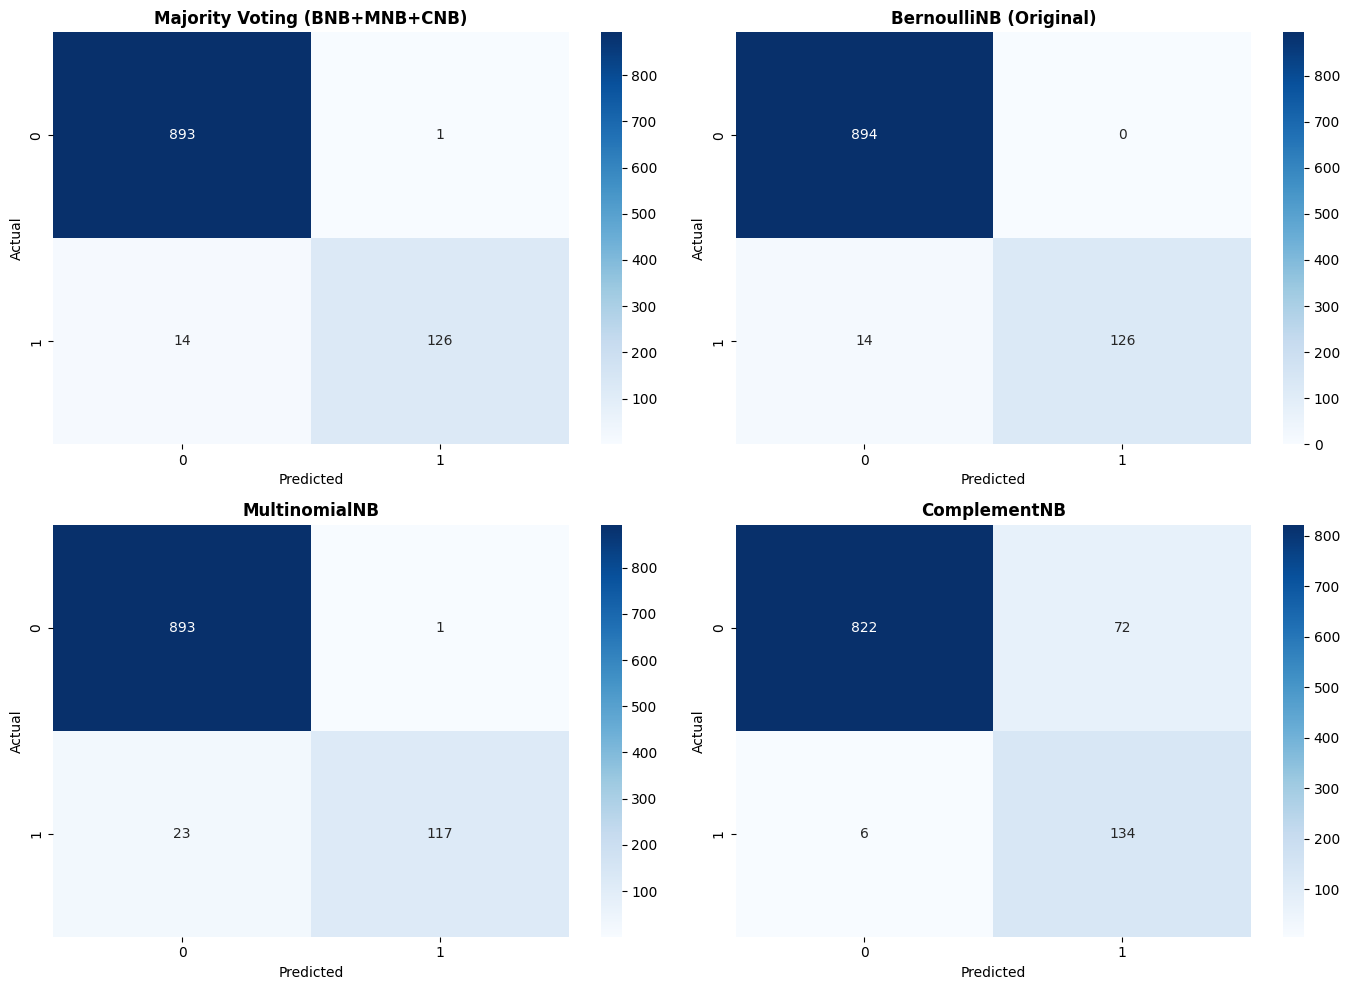

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, preds) in zip(axes.flatten(), all_models.items()):
    cm = confusion_matrix(ytest, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name, fontsize=12, weight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()


## 7. Model Serialization & Production Export
Exporting the production-ready classifier and fitted TF-IDF vectorizer into serialized pickle artifacts (`model.pkl` and `vectorizer.pkl`) for consumption by the Streamlit web application.


In [52]:
import pickle

# Save vectorizer
pickle.dump(tf, open('vectorizer.pkl', 'wb'))

# Save the winning production model (Majority Voting Ensemble)
pickle.dump(majority_voting_clf, open('model.pkl', 'wb'))

print("Production model and vectorizer serialized successfully!")


Production model and vectorizer serialized successfully!
